# 01: Train the YOLOv8 defect detector

This notebook fine-tunes YOLOv8n on the pork rasher dataset (official split, `wrinkle` removed), then evaluates it on the validation and test sets. It saves everything needed for the analysis, so that part can run without a GPU.

**Before you start**
1. **Runtime → Change runtime type → T4 GPU → Save.**
2. Put the Roboflow zip `Pork_Rasher_Error-Packaging-_v4i_yolov8.zip` in your Google Drive, in a folder called `MMA3001`.
3. Run the cells in order (**Runtime → Run all** also works). Training takes about 30-45 minutes; keep this tab open.

## 1. Check the GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Connect Google Drive and find the dataset

In [3]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

DRIVE_DIR = Path('/content/drive/MyDrive/MMA3001')
DATA_ZIP = next(DRIVE_DIR.glob('*.zip'))  # the only zip in the MMA3001 folder
assert DATA_ZIP.exists(), f'Zip not found at {DATA_ZIP}. Check the folder and file name in Drive.'
print('Found', DATA_ZIP, f'({DATA_ZIP.stat().st_size/1e6:.0f} MB)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found /content/drive/MyDrive/MMA3001/Pork Rasher Error-Packaging-.v4i.yolov8.zip (241 MB)


## 3. Get the code and install YOLO

In [4]:
%cd /content
!rm -rf 36137316-pork-rasher-inspection
!git clone -q https://github.com/mmal0078/36137316-pork-rasher-inspection
%cd /content/36137316-pork-rasher-inspection
!git log --oneline -1
!pip install -q ultralytics pytest

/content
/content/36137316-pork-rasher-inspection
293b411 (HEAD -> main, origin/main, origin/HEAD) Merge pull request #1 from mmal0078/training


## 4. Prepare the data and run the tests

This unzips the export to local disk (much faster than reading from Drive), runs the audit, and writes `data/processed`. The audit printout should report **1317 distinct images**, **0 images in more than one split** and **3 conflicting labels**.

In [5]:
!mkdir -p /content/data/raw && unzip -q -o "{DATA_ZIP}" -d /content/data/raw
!python scripts/prepare_data.py --raw /content/data/raw --out /content/data/processed | head -12
!python -m pytest -q

{
  "files": 3549,
  "distinct_images": 1317,
  "copies_per_image": {
    "1": 200,
    "2": 2,
    "3": 1115
  },
  "stems_shared_by_different_images": 45,
  "images_in_more_than_one_split": 0,
  "images_with_conflicting_labels": 3,
  "per_split": {
.................                                                        [100%]
17 passed in 0.42s


## 5. Train YOLOv8n

Settings:

| Setting | Value |
|---|---|
| Model | YOLOv8n, pretrained on COCO |
| Image size | 640 px |
| Batch | 16 |
| Epochs | up to 60, stopping early if validation mAP hasn't improved for 20 epochs |
| Seed | 0, deterministic |

Ultralytics' default augmentations are used (mosaic, flips, HSV). The epoch log prints as it goes.

In [6]:
RUN_NAME = 'yolov8n_640'
!python scripts/train_yolo.py --data /content/data/processed/data.yaml --model yolov8n.pt \
    --epochs 60 --imgsz 640 --batch 16 --device 0 --out /content/runs --name {RUN_NAME}

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/processed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_640, nbs=64, nms=None, opset=None, optimize=Fals

## 6. Quick look at the results

Training time: 43.4 min

val: mAP50 = 0.564, mAP50-95 = 0.346
   loose-meat       mAP50 = 0.335
   packaging-error  mAP50 = 0.360
   twisted-meat     mAP50 = 0.665
   unsealed         mAP50 = 0.896

test: mAP50 = 0.523, mAP50-95 = 0.239
   loose-meat       mAP50 = 0.665
   packaging-error  mAP50 = 0.526
   twisted-meat     mAP50 = 0.061
   unsealed         mAP50 = 0.842


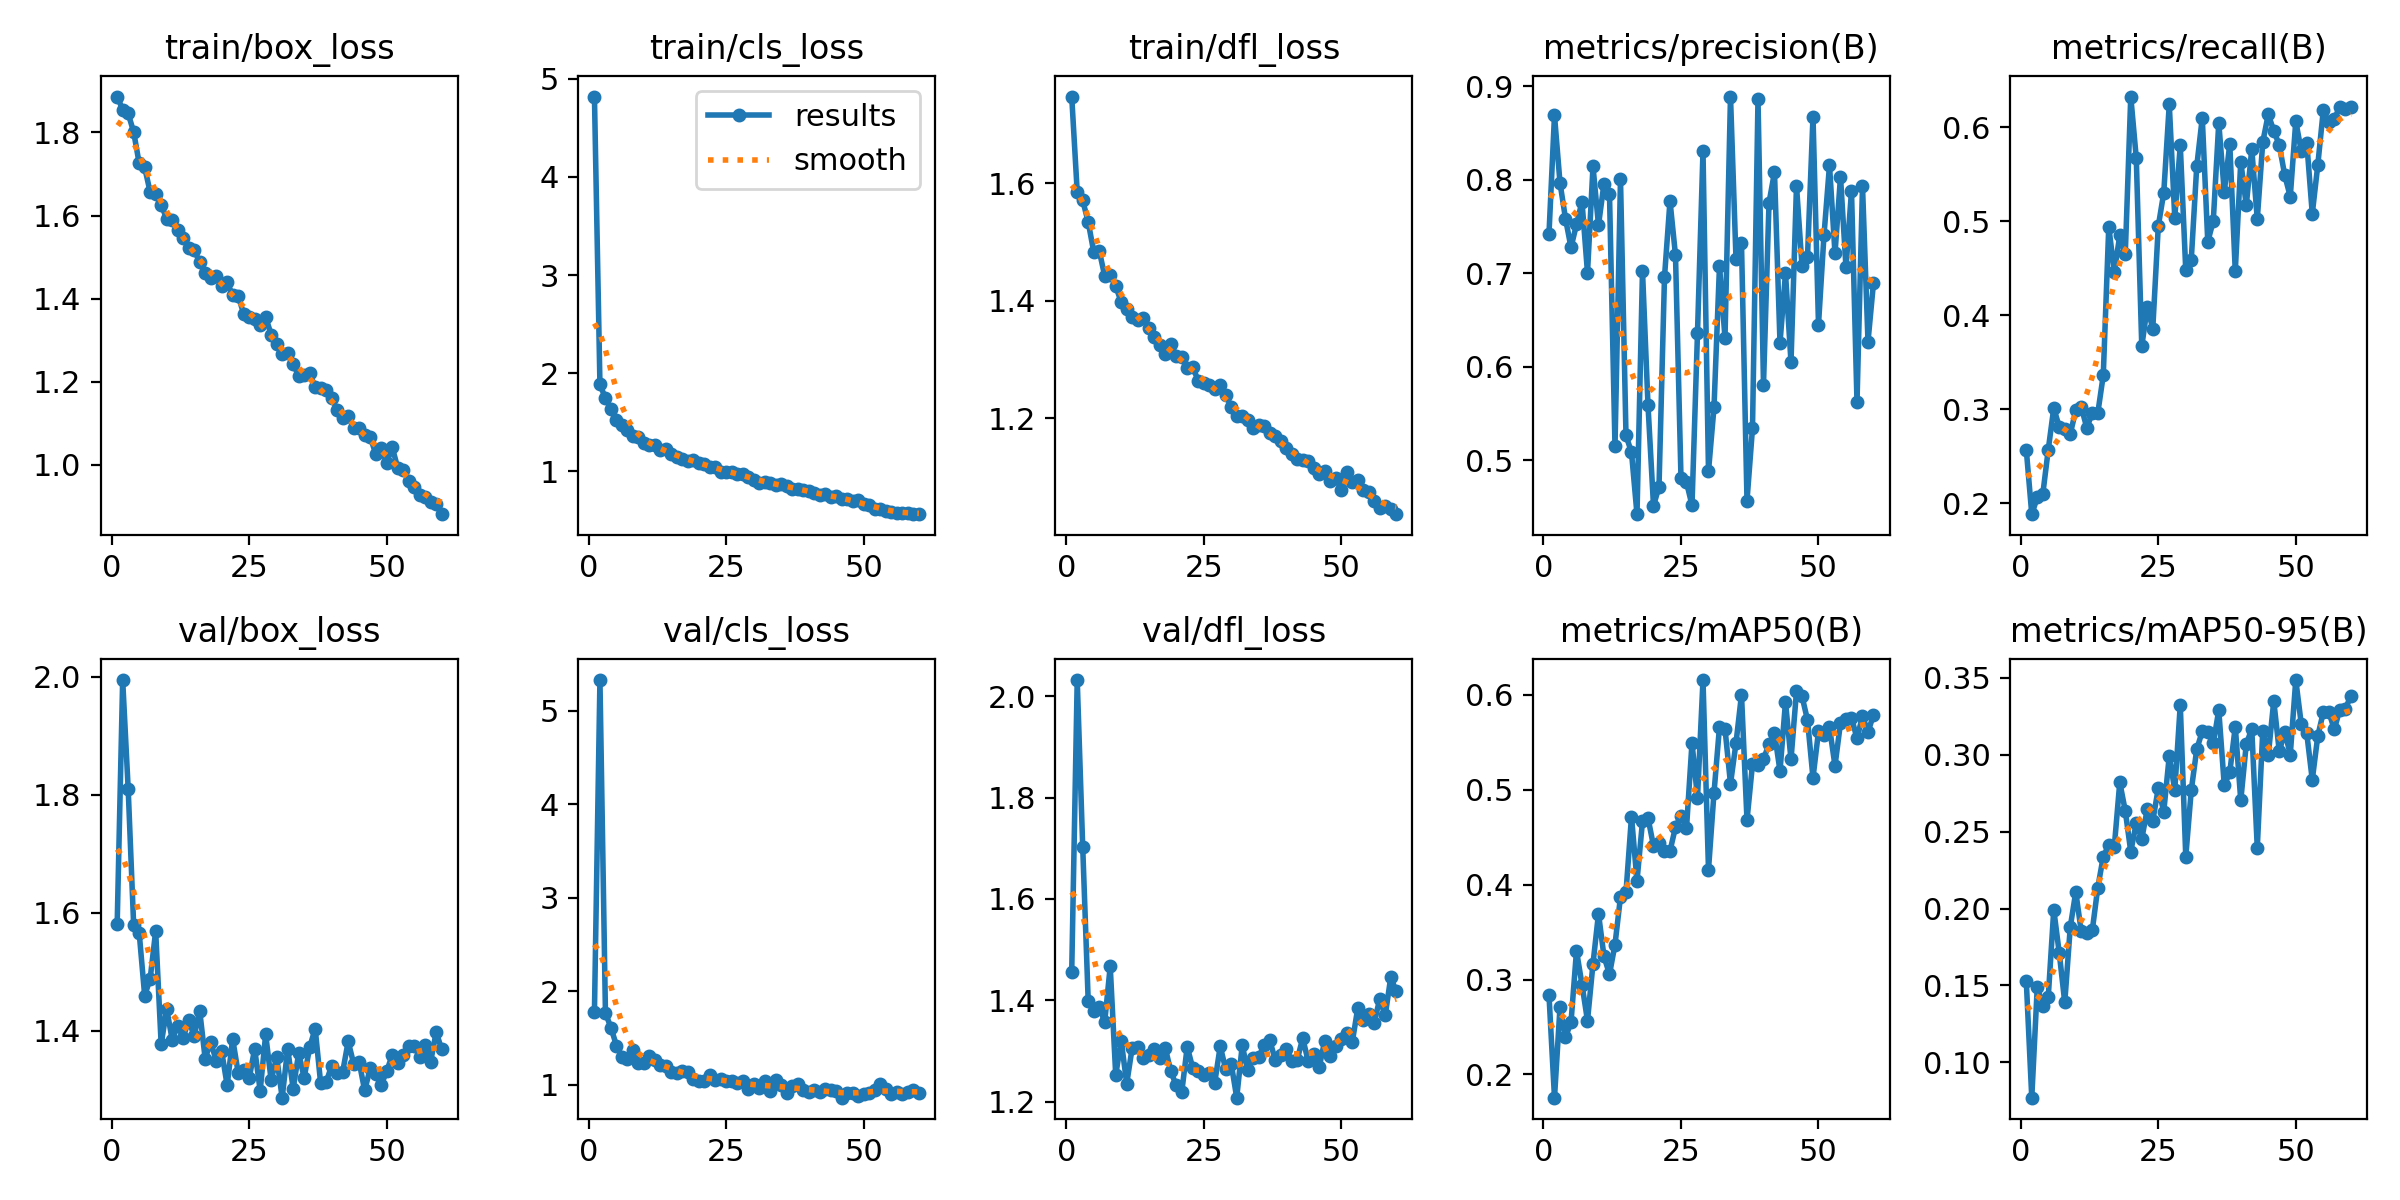

In [7]:
import json
m = json.load(open(f'/content/runs/{RUN_NAME}/metrics.json'))
print(f"Training time: {m['train_minutes']:.1f} min")
for split in ('val', 'test'):
    print(f"\n{split}: mAP50 = {m[split]['mAP50']:.3f}, mAP50-95 = {m[split]['mAP50_95']:.3f}")
    for c, v in m[split]['per_class'].items():
        print(f"   {c:16s} mAP50 = {v['mAP50']:.3f}")
from IPython.display import Image, display
display(Image(f'/content/runs/{RUN_NAME}/results.png', width=900))

## 7. Save the results to Drive

This zips the run folder (metrics, predictions, plots and weights, about 15 MB) and copies it to `MMA3001` in your Drive. **Download that zip and attach it in the chat with Claude.**

In [8]:
import shutil
z = shutil.make_archive(f'/content/{RUN_NAME}', 'zip', '/content/runs', RUN_NAME)
shutil.copy(z, DRIVE_DIR / f'{RUN_NAME}.zip')
print('Saved', DRIVE_DIR / f'{RUN_NAME}.zip')

Saved /content/drive/MyDrive/MMA3001/yolov8n_640.zip
